# Task 1: Data Handling with NumPy and Pandas

**AI/ML Volunteer Recruitment — AWS SBG**

This notebook explores a house-price dataset using Pandas, NumPy, and Matplotlib. It covers data inspection, missing-value handling, NumPy operations, descriptive statistics, grouping, and visualizations.

> **Before running:** Upload `Housing.csv` to the Colab session using the file-upload button in the Files panel, or run the upload cell below.

## 1. Import libraries and load the dataset

The notebook uses `price`, `area`, `bedrooms`, and `parking` from `Housing.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# If Housing.csv is not already available in the Colab session,
# uncomment and run the next two lines to upload it:
# from google.colab import files
# files.upload()

complex_df = pd.read_csv("Housing.csv")
df = complex_df[["price", "area", "bedrooms", "parking"]].copy()

print("Dataset shape (rows, columns):", df.shape)
print("\nColumn data types:")
print(df.dtypes)
print("\nDataFrame information:")
df.info()


Dataset shape (rows, columns): (545, 4)

Column data types:
price       int64
area        int64
bedrooms    int64
parking     int64
dtype: object

DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   price     545 non-null    int64
 1   area      545 non-null    int64
 2   bedrooms  545 non-null    int64
 3   parking   545 non-null    int64
dtypes: int64(4)
memory usage: 17.2 KB


## 2. Preview the data and descriptive summary

In [2]:
n = 7
print(f"First {n} rows:")
display(df.head(n))

print("Descriptive statistics:")
display(df.describe())


First 7 rows:


,price,area,bedrooms,parking
0,13300000,7420,4,2
1,12250000,8960,4,3
2,12250000,9960,3,2
3,12215000,7500,4,3
4,11410000,7420,4,2
5,10850000,7500,3,2
6,10150000,8580,4,2


Descriptive statistics:


,price,area,bedrooms,parking
count,5.450000e+02,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,0.693578
std,1.870440e+06,2170.141023,0.738064,0.861586
min,1.750000e+06,1650.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,3.000000


## 3. Handle missing values

To practise data cleaning, this section randomly masks approximately 5% of the selected data cells. This is an artificial exercise; it does not mean the original dataset had missing values. Missing numerical values are filled with their respective column medians, which are less sensitive to extreme values than means.

In [3]:
rng = np.random.default_rng(27)

df_missing = df.copy()
mask = rng.random(df_missing.shape) < 0.05
df_missing = df_missing.mask(mask)

print("Missing values before cleaning:")
display(df_missing.isnull().sum().to_frame("missing_count"))

df_clean = df_missing.copy()
for col in df_clean.columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after cleaning:")
display(df_clean.isnull().sum().to_frame("missing_count"))
print("\nCleaned dataset shape:", df_clean.shape)


Missing values before cleaning:


,missing_count
price,32
area,29
bedrooms,28
parking,23


Missing values after cleaning:


,missing_count
price,0
area,0
bedrooms,0
parking,0



Cleaned dataset shape: (545, 4)


## 4. NumPy operations

In [4]:
# Convert Pandas columns to NumPy arrays
area_array = df_clean["area"].to_numpy()
price_array = df_clean["price"].to_numpy()

# Calculate price per square foot
# (The dataset's area units are assumed to be square feet for this calculation.)
df_clean["price_per_sqft"] = price_array / area_array

# Min-max normalize area
area_min = np.min(area_array)
area_max = np.max(area_array)

if area_max != area_min:
    df_clean["area_normalized"] = (area_array - area_min) / (area_max - area_min)
else:
    df_clean["area_normalized"] = 0.0

# Boolean mask: houses larger than 2,000 area units
large_houses = df_clean[area_array > 2000]

print("First five price-per-square-foot values:")
display(df_clean[["price_per_sqft"]].head())

print("First five normalized area values:")
display(df_clean[["area_normalized"]].head())

print("Number of houses with area greater than 2,000:", len(large_houses))
print("Sample of houses larger than 2,000:")
display(large_houses.head())


First five price-per-square-foot values:


,price_per_sqft
0,1792.452830
1,1367.187500
2,1229.919679
3,1628.666667
4,1537.735849


First five normalized area values:


,area_normalized
0,0.413620
1,0.524014
2,0.595699
3,0.419355
4,0.413620


Number of houses with area greater than 2,000: 538
Sample of houses larger than 2,000:


,price,area,bedrooms,parking,price_per_sqft,area_normalized
0,13300000.0,7420.0,4.0,2.0,1792.452830,0.413620
1,12250000.0,8960.0,3.0,3.0,1367.187500,0.524014
2,12250000.0,9960.0,3.0,2.0,1229.919679,0.595699
3,12215000.0,7500.0,4.0,3.0,1628.666667,0.419355
4,11410000.0,7420.0,4.0,2.0,1537.735849,0.413620


## 5. Descriptive statistics

The following statistics are calculated on the original selected DataFrame, before the artificial missing values are introduced. Each column's mean, median, standard deviation, minimum, and maximum are displayed.

In [5]:
key_columns = ["price", "area", "bedrooms", "parking"]

stats = df[key_columns].agg(["mean", "median", "std", "min", "max"]).T
display(stats)


,mean,median,std,min,max
price,4.766729e+06,4340000.0,1.870440e+06,1750000.0,13300000.0
area,5.150541e+03,4600.0,2.170141e+03,1650.0,16200.0
bedrooms,2.965138e+00,3.0,7.380639e-01,1.0,6.0
parking,6.935780e-01,0.0,8.615858e-01,0.0,3.0


## 6. Correlation analysis

In [6]:
correlation = df[["area", "bedrooms", "price"]].corr()
display(correlation)

print("Correlation values range from -1 to +1.")
print("Values closer to +1 indicate a stronger positive linear relationship;")
print("values closer to -1 indicate a stronger negative linear relationship.")


,area,bedrooms,price
area,1.000000,0.151858,0.535997
bedrooms,0.151858,1.000000,0.366494
price,0.535997,0.366494,1.000000


Correlation values range from -1 to +1.
Values closer to +1 indicate a stronger positive linear relationship;
values closer to -1 indicate a stronger negative linear relationship.


## 7. Average price by number of bedrooms

In [7]:
average_price_by_bedrooms = df.groupby("bedrooms")["price"].mean().reset_index()
average_price_by_bedrooms = average_price_by_bedrooms.rename(
    columns={"price": "average_price"}
)
display(average_price_by_bedrooms)


,bedrooms,average_price
0,1,2.712500e+06
1,2,3.632022e+06
2,3,4.954598e+06
3,4,5.729758e+06
4,5,5.819800e+06
5,6,4.791500e+06


## 8. Visualizations

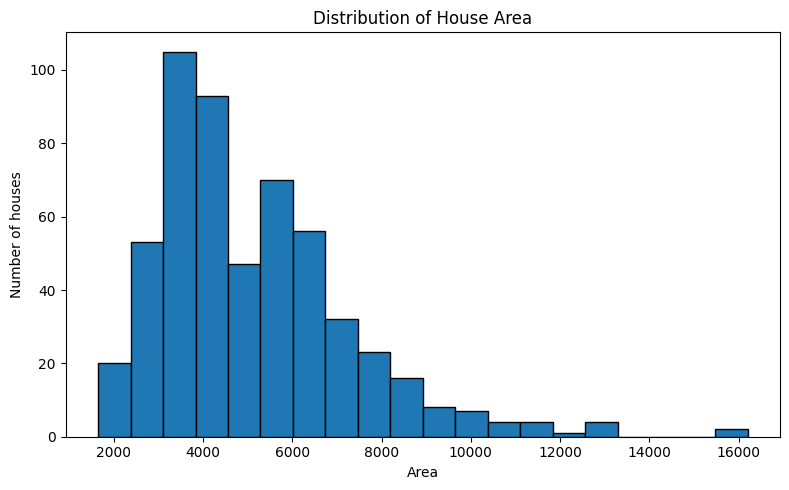

In [8]:
# Histogram of house area
plt.figure(figsize=(8, 5))
plt.hist(df["area"], bins=20, edgecolor="black")
plt.title("Distribution of House Area")
plt.xlabel("Area")
plt.ylabel("Number of houses")
plt.tight_layout()
plt.show()


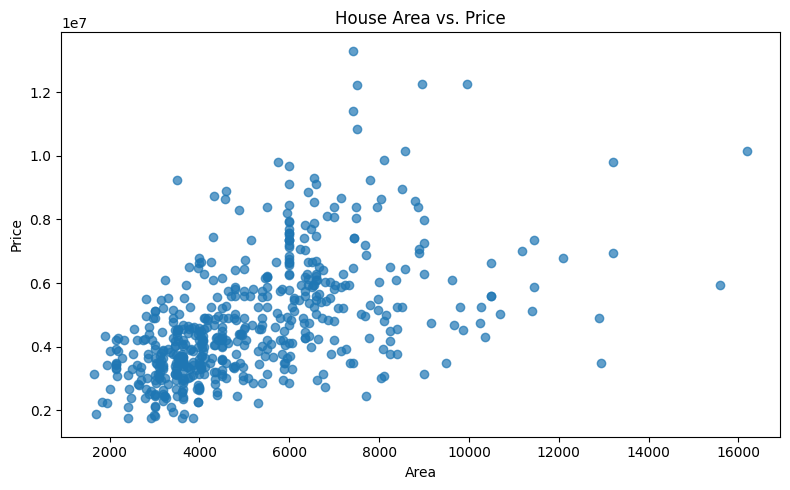

In [9]:
# Scatter plot of area versus price
plt.figure(figsize=(8, 5))
plt.scatter(df["area"], df["price"], alpha=0.7)
plt.title("House Area vs. Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


## 9. Observations

After running the notebook, write 3–4 observations based on the actual output. Use the prompts below and replace them with conclusions supported by your results:

1. **Area and price:** What does the correlation value suggest about the relationship between area and price?
2. **Bedrooms and price:** How does price vary across bedroom groups?
3. **Distribution:** Does the histogram show most houses concentrated in a particular area range, or is the distribution skewed?
4. **Data cleaning:** How many missing values were introduced and handled, and why was the median chosen?

Do not claim a relationship or result unless it is supported by the output above.

## Summary

This notebook practises loading and inspecting tabular data, median imputation, NumPy array operations, min-max normalization, Boolean filtering, descriptive statistics, correlation analysis, grouping, and basic data visualization.

**Dataset source:** Add the original public dataset URL and attribution here if applicable.